# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [2]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5


# 1. Compute linear combination z
z = S @ theta + bias
print(z)
# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))
print(probabilities)
# Identify predicted spam emails
predicted_spam =probabilities>= 0.5
print(predicted_spam)

[6.3 1.8 4.7 2.2]
[0.99816706 0.85814894 0.9909867  0.90024951]
[ True  True  True  True]


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [3]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [5]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"
log.loc[rng.choice(n, 12, replace=False), "failed_attempts"] = rng.integers(5, 12, 12)
# Write your code here

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [8]:
# Insert 10 missing values randomly

# Write your code here
log.loc[rng.choice(n, 10, replace=False), "duration_min"] = np.nan
print(log.isna().sum())

user                0
hour                0
failed_attempts     0
country             0
duration_min       30
dtype: int64


In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [10]:
# Write your code here

ru_log_at_least_five_attempts = log[
    (log["failed_attempts"] >= 5) & (log["country"] == "RU")
]
print(len(ru_log_at_least_five_attempts))

3


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [11]:
# Write your code here

user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
       .sum()
       .sort_values(ascending=False)
)
print(user_max_failed_attempts)

user
yacine    82
sara      75
ali       53
nour      49
karim     37
Name: failed_attempts, dtype: int64


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [12]:
# Write your code here
log["long_session"] = (log["duration_min"] > 30).astype(int)
print(log[["duration_min", "long_session"]])

     duration_min  long_session
0            24.0             0
1            23.2             0
2             4.8             0
3             4.2             0
4             NaN             0
..            ...           ...
295           5.2             0
296           NaN             0
297           5.0             0
298          61.0             1
299           7.2             0

[300 rows x 2 columns]


In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

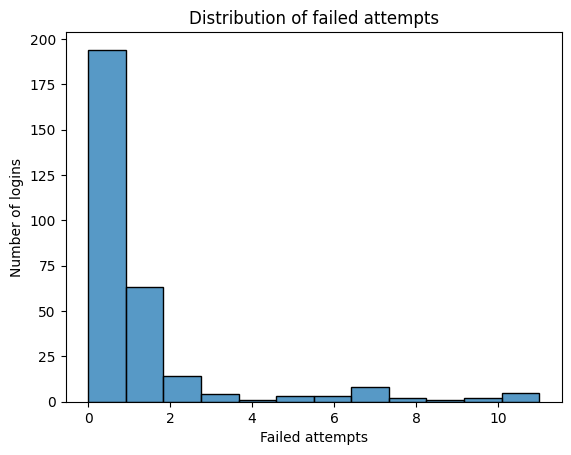

In [13]:
# Draw the histogram of failed_attempts.
# Write your code here
# Histogram of failed_attempts
sns.histplot(data=log, x="failed_attempts", bins=12)
plt.title("Distribution of failed attempts")
plt.xlabel("Failed attempts")
plt.ylabel("Number of logins")
plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
# answer_q2 = B

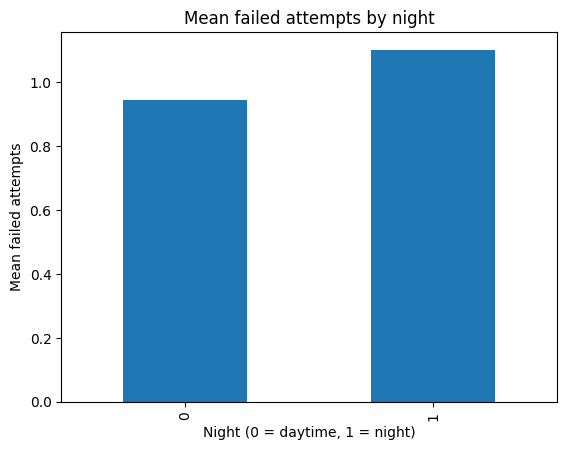

In [14]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
log["night"] = (log["hour"] < 6).astype(int)
meanfailed = log.groupby("night")["failed_attempts"].mean()
meanfailed.plot.bar()
plt.title("Mean failed attempts by night")
plt.xlabel("Night (0 = daytime, 1 = night)")
plt.ylabel("Mean failed attempts")
plt.show()


In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [16]:
# Write your code here
# Please write a sentence response instead of code
print("it return the third column of X for all 300 row in array")

it return the third column of X for all 300 row in array


Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [18]:
# Write your code here
df.isna().sum()

NameError: name 'df' is not defined

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

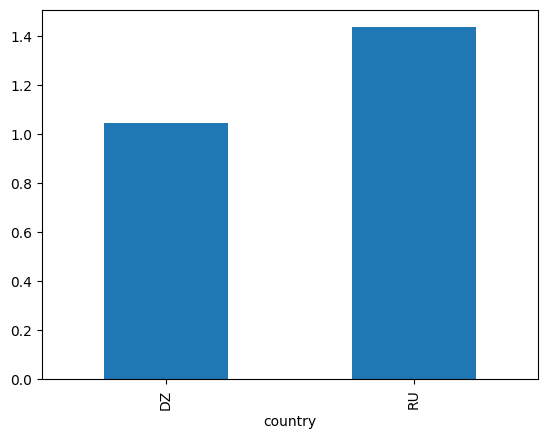

In [20]:
# Write your code here
log[log["country"].isin(["RU", "DZ"])].groupby("country")["failed_attempts"].mean().plot.bar()
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [19]:
# Write your code here
print("It ensures that different features are measured on a similar scale, which improves the performance and accuracy of many statistical and machine learning models ")

It ensures that different features are measured on a similar scale, which improves the performance and accuracy of many statistical and machine learning models 


Commit the logins_clean.csv.(0.5 point)

In [28]:
# save the cleaned table in login_clean.csv
# Write your code here
# Replace missing duration values with the median, as in Workshop 1
median = log["duration_min"].median()
log["duration_min"] = log["duration_min"].fillna(median)

# Add the night feature
log["night"] = (log["hour"] < 6).astype(int)

# Save the cleaned table
log.to_csv("logins_clean.csv", index=False)

print("logins_clean.csv saved")
log.to_csv("logins_clean.csv", index=False)

logins_clean.csv saved


In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [29]:
# Write your code here

cols = ["hour", "failed_attempts", "duration_min", "night"]
X=log[cols].to_numpy()
X_scale= (X - X.mean(axis=0)) / X.std(axis=0)
print(X_scale.shape)

(300, 4)
(300, 4)


In [ ]:
import numpy as np
import pandas as pd
